# Modelling Stock Price Movements with Stochastic Processes
**Case study: Apple Inc. (AAPL), daily data July 2021 – July 2026**

This notebook is the code deliverable (File 1). It reproduces every number and figure in the report
`Stochastic_Stock_Models_Report.docx` / `.pdf`.

## README: how to run
1. **Install dependencies** (Python ≥ 3.10):
   ```bash
   pip install -r requirements.txt
   ```
2. **Run the notebook** top to bottom (*Kernel → Restart & Run All*), or run the whole pipeline from a terminal:
   ```bash
   python stock_models.py                                # uses data/AAPL_raw.csv (offline)
   python stock_models.py --source yfinance --tickers AAPL MSFT KO   # fresh download, needs internet
   ```
3. **Outputs**: figures in `figures/`, the cleaned series in `data/AAPL_clean.csv`, and all
   parameters and risk tables in `results_AAPL.json`.

**Project layout**

| File | Purpose |
|---|---|
| `stock_models.py` | Data loading/cleaning, calibration, SDE simulators, risk metrics, backtests |
| `plots.py` | All figures (fixed colour per model: GBM blue, OU orange, Merton green) |
| `Stochastic_Stock_Models.ipynb` | This notebook: narrative walk-through of the analysis |
| `data/AAPL_raw.csv` | Raw yfinance export (adjusted OHLCV) |

The random seed is fixed (`seed=42`), so the results are reproducible. Monte Carlo uses **10,000 paths** per model,
above the 1,000-run minimum, so tail quantiles (VaR, CVaR) are stable to about ±0.5 percentage points.

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import stock_models as sm
import plots

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)

## 1. Data collection

The data are AAPL daily OHLCV bars downloaded from Yahoo Finance with `yfinance`
(split- and dividend-adjusted, `auto_adjust=True`), covering 13 Jul 2021 – 13 Jul 2026.
The export is a public CSV (Jonasmiles, 2026); `sm.download_yfinance()` reproduces it directly
when Yahoo Finance is reachable.

In [2]:
raw = sm.load_yfinance_csv("data/AAPL_raw.csv", ticker="AAPL")
print(raw.shape)
raw.head()

(1255, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2021-07-13,141.9629,143.7369,140.0036,140.3935,100827100
2021-07-14,145.3843,145.7937,143.9514,144.3608,127050800
2021-07-15,144.7312,146.2128,143.3763,145.4720,106820300
2021-07-16,142.6939,145.9788,142.1968,144.7117,93251400
2021-07-19,138.8534,140.4325,138.0931,140.1206,121434600


## 2. Cleaning and preprocessing
`clean_prices` sorts by date, removes duplicate dates, treats non-positive prices as missing, fills gaps of
at most 2 days by time interpolation, and **flags (but keeps)** returns more than 6 robust standard
deviations from the median. Such moves are real market events, and they matter for tail risk.

In [3]:
prices, report = sm.clean_prices(raw)
print(json.dumps(report, indent=2))
prices.to_csv("data/AAPL_clean.csv", header=["Close"])

{
  "rows_raw": 1255,
  "bad_dates": 0,
  "duplicate_dates": 0,
  "missing_or_nonpositive": 0,
  "flagged_outliers": {
    "2022-11-10": 0.0852,
    "2025-04-03": -0.097,
    "2025-04-09": 0.1426
  },
  "rows_clean": 1255,
  "start": "2021-07-13",
  "end": "2026-07-13"
}


In [4]:
# Calibration window: the most recent 2 years (504 trading days)
CALIB_DAYS = 504
calib = prices.iloc[-(CALIB_DAYS + 1):]
r = sm.log_returns(calib)
print("Calibration window:", calib.index[0].date(), "to", calib.index[-1].date(), "| S0 =", round(calib.iloc[-1], 2))
pd.Series(sm.describe_returns(r)).to_frame("calibration window").join(
    pd.Series(sm.describe_returns(sm.log_returns(prices))).to_frame("full 5-year sample"))

Calibration window: 2024-07-08 to 2026-07-13 | S0 = 316.15


,calibration window,full 5-year sample
n_obs,504.0000,"1,254.0000"
mean_daily,0.0007,0.0006
std_daily,0.0177,0.0174
ann_mean_log_return,0.1681,0.1609
ann_volatility,0.2817,0.2769
skewness,0.3526,0.2227
excess_kurtosis,10.5650,5.7326
min,-0.0970,-0.0970
max,0.1426,0.1426
jarque_bera_stat,"2,354.4353","1,727.4577"


**Stylised facts.** Excess kurtosis is far above 0 and Jarque–Bera rejects normality, so returns are fat-tailed.
Returns themselves show little autocorrelation (Ljung–Box on *r*), but squared returns are strongly autocorrelated
(Ljung–Box on *r²*): volatility clusters.

In [5]:
pd.Series(sm.stationarity_tests(calib))

adf_c_stat    -0.8384
adf_c_p        0.8076
adf_ct_stat   -2.1575
adf_ct_p       0.5138
dtype: float64

ADF tests on the log price fail to reject a unit root, with or without a trend. This supports the random-walk
(GBM) view and warns that mean reversion is **not** statistically established for this stock.

## 3. Model calibration
* **GBM**: maximum likelihood on i.i.d. normal log returns.
* **OU (trend)**: exact AR(1) representation of the OU deviation from a linear log-price trend.
* **Merton jump-diffusion**: maximum likelihood on the Poisson mixture density, with λ capped at 12 jumps/year
  (see the docstring of `fit_merton` for why the cap is needed).

In [6]:
params = sm.calibrate_all(calib)
for name, p in params.items():
    print(f"{name:11s}", p)
ou = params["OU (trend)"]
print(f"\nOU half-life: {ou.half_life_days:.1f} trading days; today's log deviation from trend: {ou.y0:+.3f}"
      f" (price {np.exp(ou.y0)-1:+.1%} vs trend)")
plain = sm.fit_ou(calib, trend=False)
print(f"Plain OU (no trend): theta={plain.theta:.2f}, half-life={plain.half_life_days:.0f} days")
mer = params["Merton JD"]
print(f"Merton: total vol={mer.total_vol:.3f}, jump share of variance="
      f"{mer.lam*(mer.mu_j**2+mer.sigma_j**2)/mer.total_vol**2:.1%}")

GBM         GBMParams(mu=0.2078312112296159, sigma=0.2817380591018695)
OU (trend)  OUParams(theta=5.035167223479, sigma=0.28323099198794705, a=5.335327876170183, g=0.146068689126108, t0=2.0, y0=0.12875151077646496)
Merton JD   MertonParams(mu=0.22789521067773422, sigma=0.215265466843557, lam=12.0, mu_j=-0.00932473954380213, sigma_j=0.0467015740066775)

OU half-life: 34.7 trading days; today's log deviation from trend: +0.129 (price +13.7% vs trend)
Plain OU (no trend): theta=1.50, half-life=116 days
Merton: total vol=0.271, jump share of variance=37.0%


In [7]:
sm.model_loglik(r, calib, *params.values())

,loglik,params,AIC,BIC
model,,,,
GBM,"1,317.2270",2,"-2,630.4539","-2,622.0088"
OU (trend),"1,319.5762",4,"-2,631.1524","-2,614.2621"
Merton JD,"1,370.2100",5,"-2,730.4201","-2,709.3072"


## 4. Monte Carlo simulation
Each model is simulated with its **exact** transition law for 180 trading days and 10,000 paths. The 30- and 60-day
results are read off the same paths.

In [8]:
S0 = float(calib.iloc[-1])
HORIZONS = [30, 60, 180]
sims = sm.simulate_all(S0, params, n_days=max(HORIZONS), n_paths=10_000, seed=42)
summary = sm.summary_table(sims, S0, HORIZONS)
summary[["mean_price", "median_price", "p05_price", "p95_price", "expected_return",
         "prob_loss", "prob_loss_gt_10", "prob_gain_gt_10", "VaR95", "CVaR95", "median_max_drawdown"]]

mean_price  median_price  p05_price  p95_price  expected_return  prob_loss  prob_loss_gt_10  prob_gain_gt_10  VaR95  CVaR95  \
model      horizon                                                                                                                                
GBM        30         324.0717      322.2718   275.2525   378.0137           0.0251     0.4194           0.0975           0.2181 0.1294  0.1643   
           60         331.6806      328.7644   263.4946   411.2223           0.0491     0.3856           0.1413           0.3367 0.1666  0.2134   
           180        367.3803      356.8552   242.6688   527.0145           0.1620     0.3032           0.1686           0.5474 0.2324  0.2987   
OU (trend) 30         304.3789      303.3339   268.6855   343.4030          -0.0372     0.7102           0.1940           0.0359 0.1501  0.1789   
           60         299.9533      298.7437   259.6187   344.4314          -0.0512     0.7469           0.2800           0.0379 0.1788  0.2070   
           180        311.2302      309.9100   267.8716   358.8495          -0.0156     0.5858           0.1708           0.0996 0.1527  0.1825   
Merton JD  30         325.1018      324.4538   277.0893   375.3949           0.0283     0.3909           0.0816           0.2150 0.1236  0.1621   
           60         334.4858      332.2658   266.2880   409.4540           0.0580     0.3524           0.1196           0.3595 0.1577  0.2064   
           180        373.9170      364.3249   250.7864   524.5105           0.1827     0.2572           0.1327           0.5812 0.2067  0.2833   

                    median_max_drawdown  
model      horizon                       
GBM        30                    0.0803  
           60                    0.1157  
           180                   0.1890  
OU (trend) 30                    0.1045  
           60                    0.1489  
           180                   0.2108  
Merton JD  30                    0.0697  
           60                    0.1023  
           180                   0.1736

## 5. Out-of-sample evaluation
* **Hold-out**: calibrate on the 504 days ending 21 Oct 2025, simulate 180 days, and compare with the realised path.
* **Rolling backtest**: 73 origins, 10 days apart (Jul 2023 – May 2026), each with a 30-day forecast. Each forecast
  records its PIT and whether the realised price fell inside the 90% interval (Kupiec test).

In [9]:
res = sm.run_pipeline(prices, calib_days=CALIB_DAYS, n_paths=10_000, seed=42, make_plots=True)
ho = res["holdout"]; realised = ho["test"].iloc[-1]
for name, paths in ho["sims"].items():
    st = paths[:, -1]
    print(f"{name:11s} median {np.median(st):7.2f}  90% [{np.quantile(st,.05):6.1f}, {np.quantile(st,.95):6.1f}]"
          f"  realised {realised:.2f}  PIT {np.mean(st < realised):.2f}")
res["backtest_summary"]

GBM         median  300.32  90% [ 205.5,  443.6]  realised 316.15  PIT 0.58
OU (trend)  median  264.09  90% [ 228.3,  307.1]  realised 316.15  PIT 0.98
Merton JD   median  302.98  90% [ 208.9,  437.2]  realised 316.15  PIT 0.58


,forecasts,coverage90,kupiec_p,mean_log_score,pit_ks_p
model,,,,,
GBM,73,0.9452,0.1625,1.0629,0.5304
OU (trend),73,0.8493,0.1758,1.1127,0.2803
Merton JD,73,0.9315,0.3441,1.0725,0.6060


## 6. Figures
`run_pipeline(..., make_plots=True)` above wrote every figure to `figures/`. They are displayed below.

### Price history and daily log returns

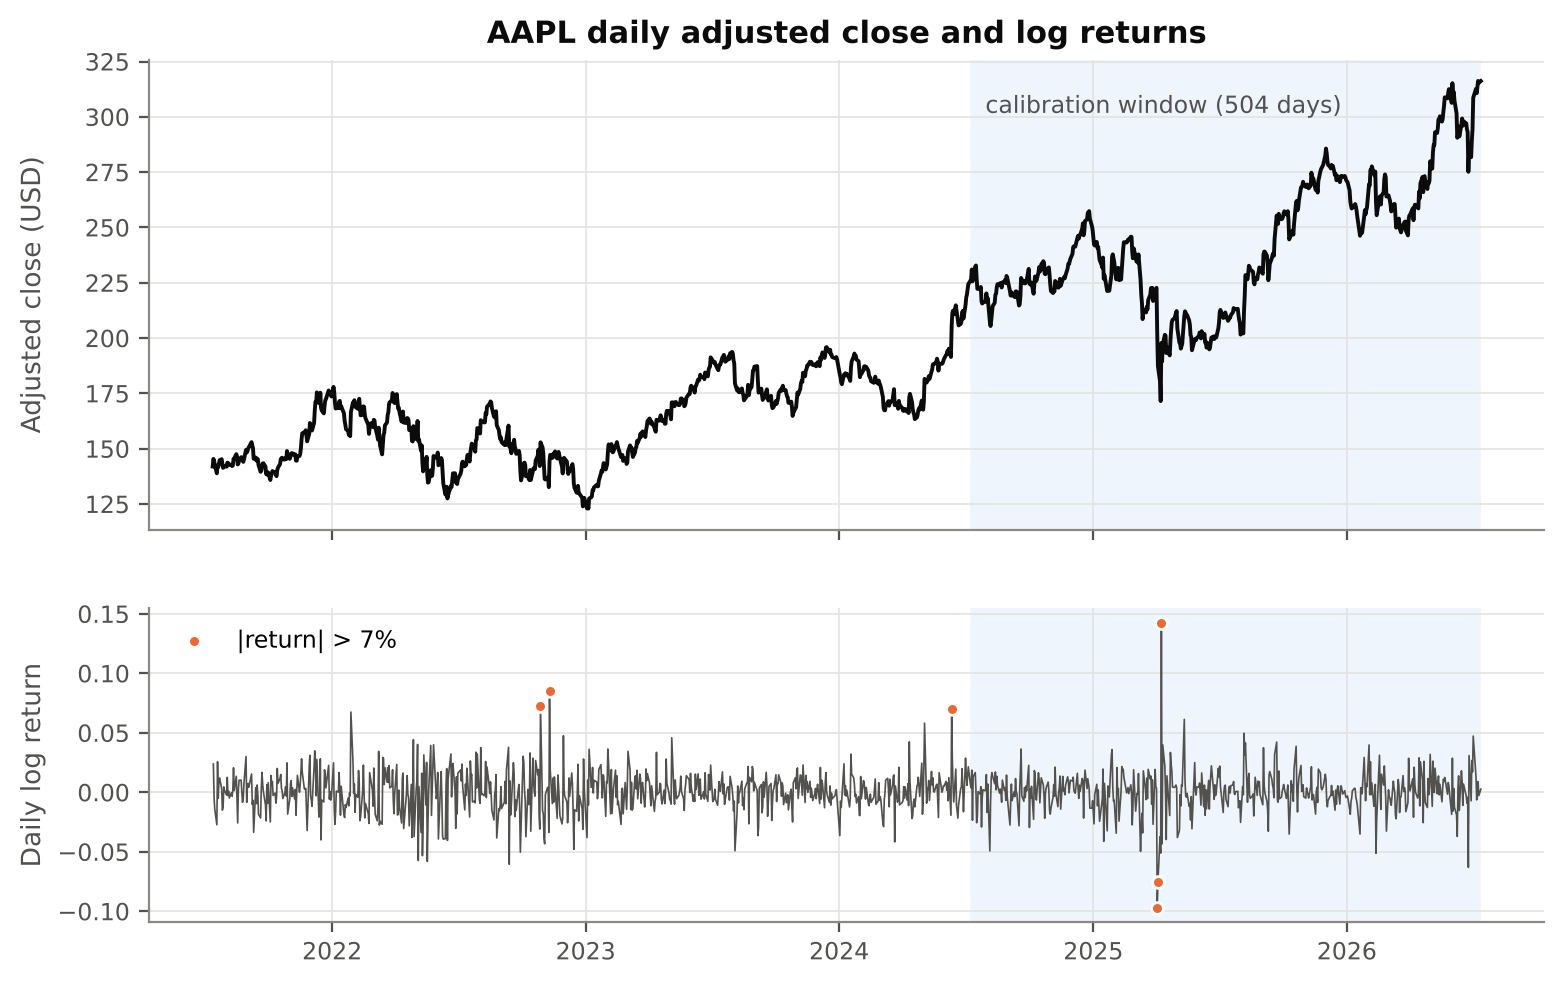

In [10]:
display(Image("figures/fig1_price_history.png", width=900))

### Return distribution vs GBM and Merton densities; Q–Q plot

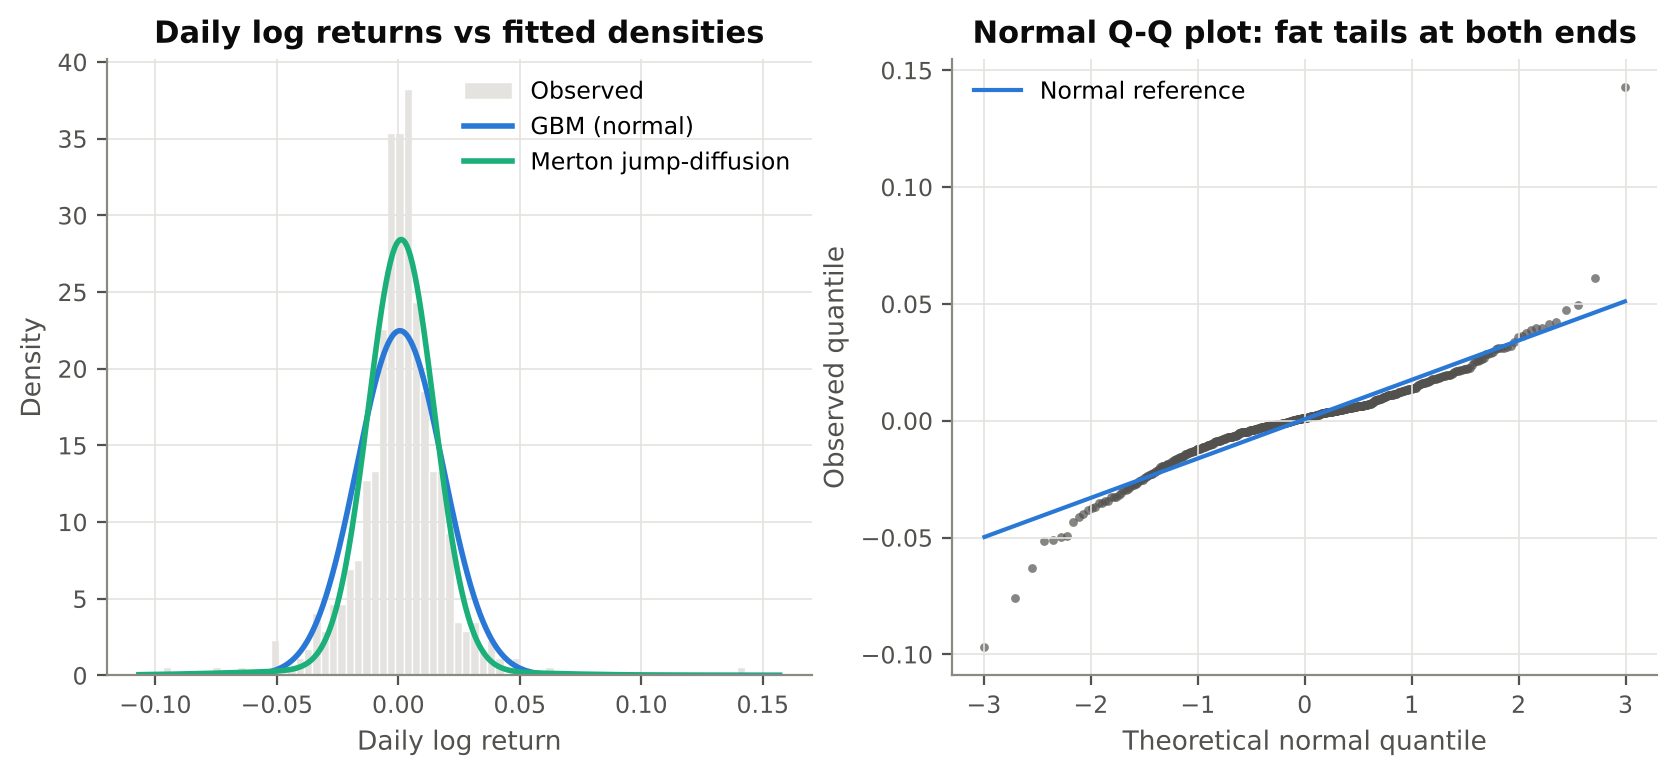

In [11]:
display(Image("figures/fig2_return_distribution.png", width=900))

### Simulated paths with mean, median, 50% and 90% intervals

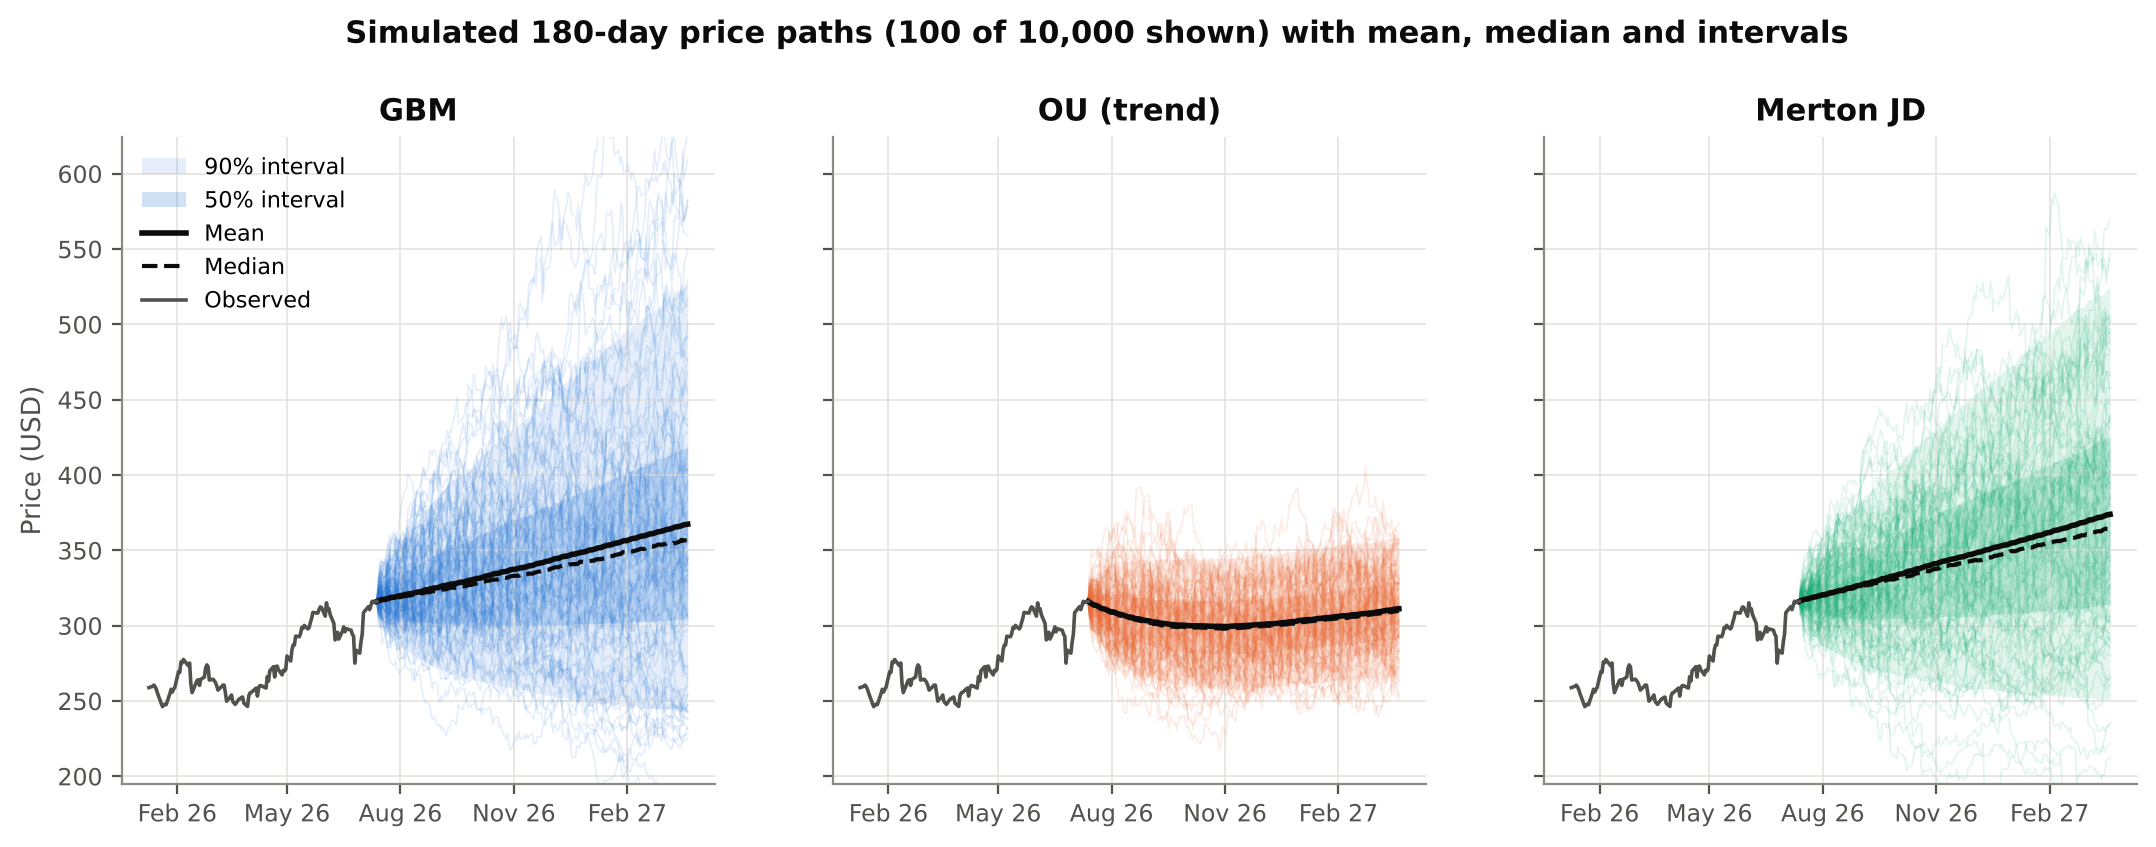

In [12]:
display(Image("figures/fig3_sample_paths.png", width=900))

### Model comparison of median forecasts and 90% intervals

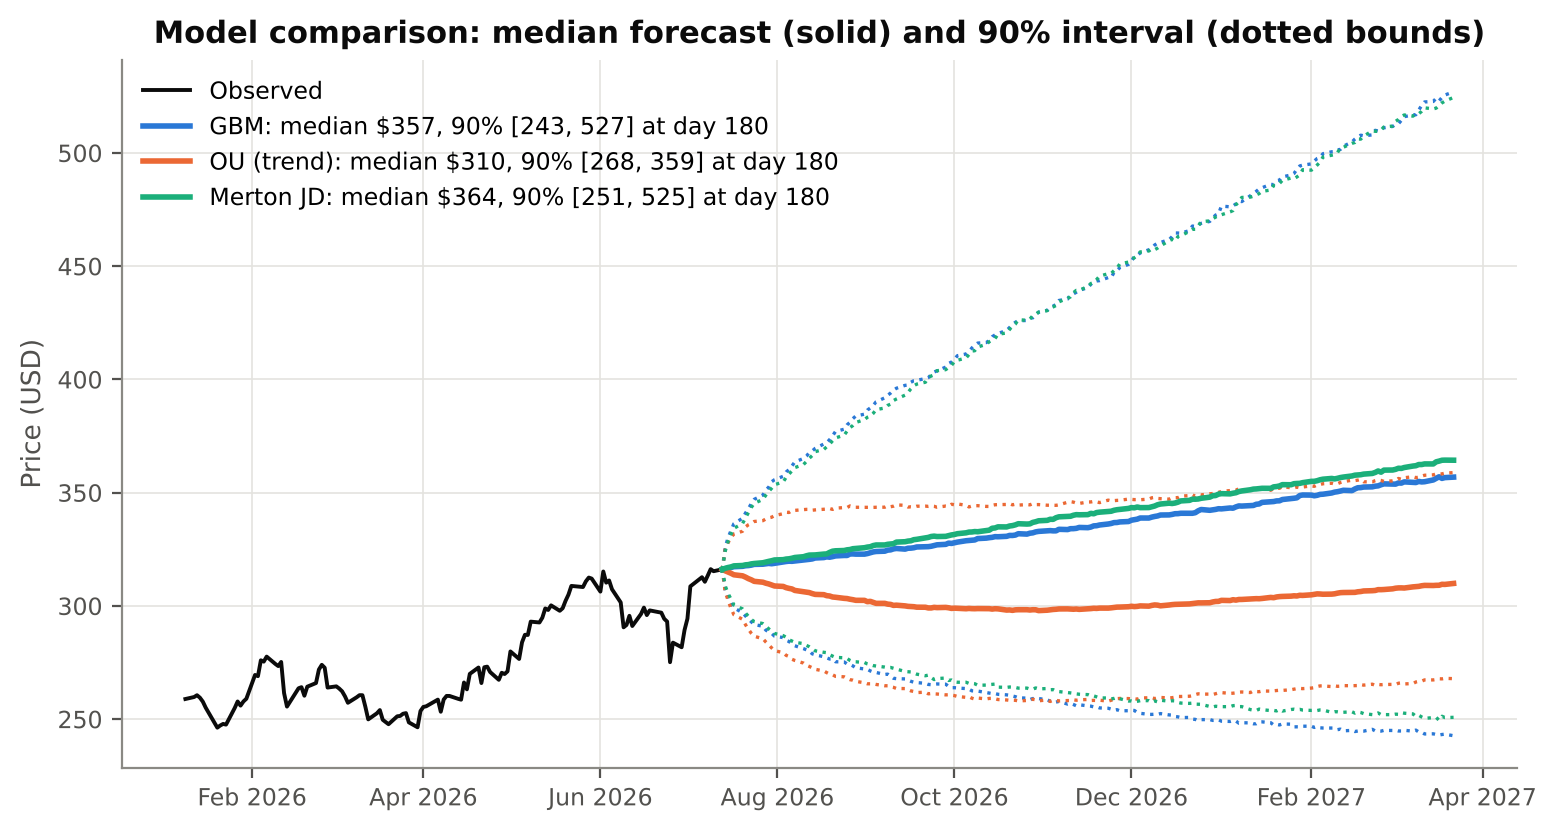

In [13]:
display(Image("figures/fig4_model_comparison_fan.png", width=900))

### Distribution of the simulated price at 30, 60 and 180 days

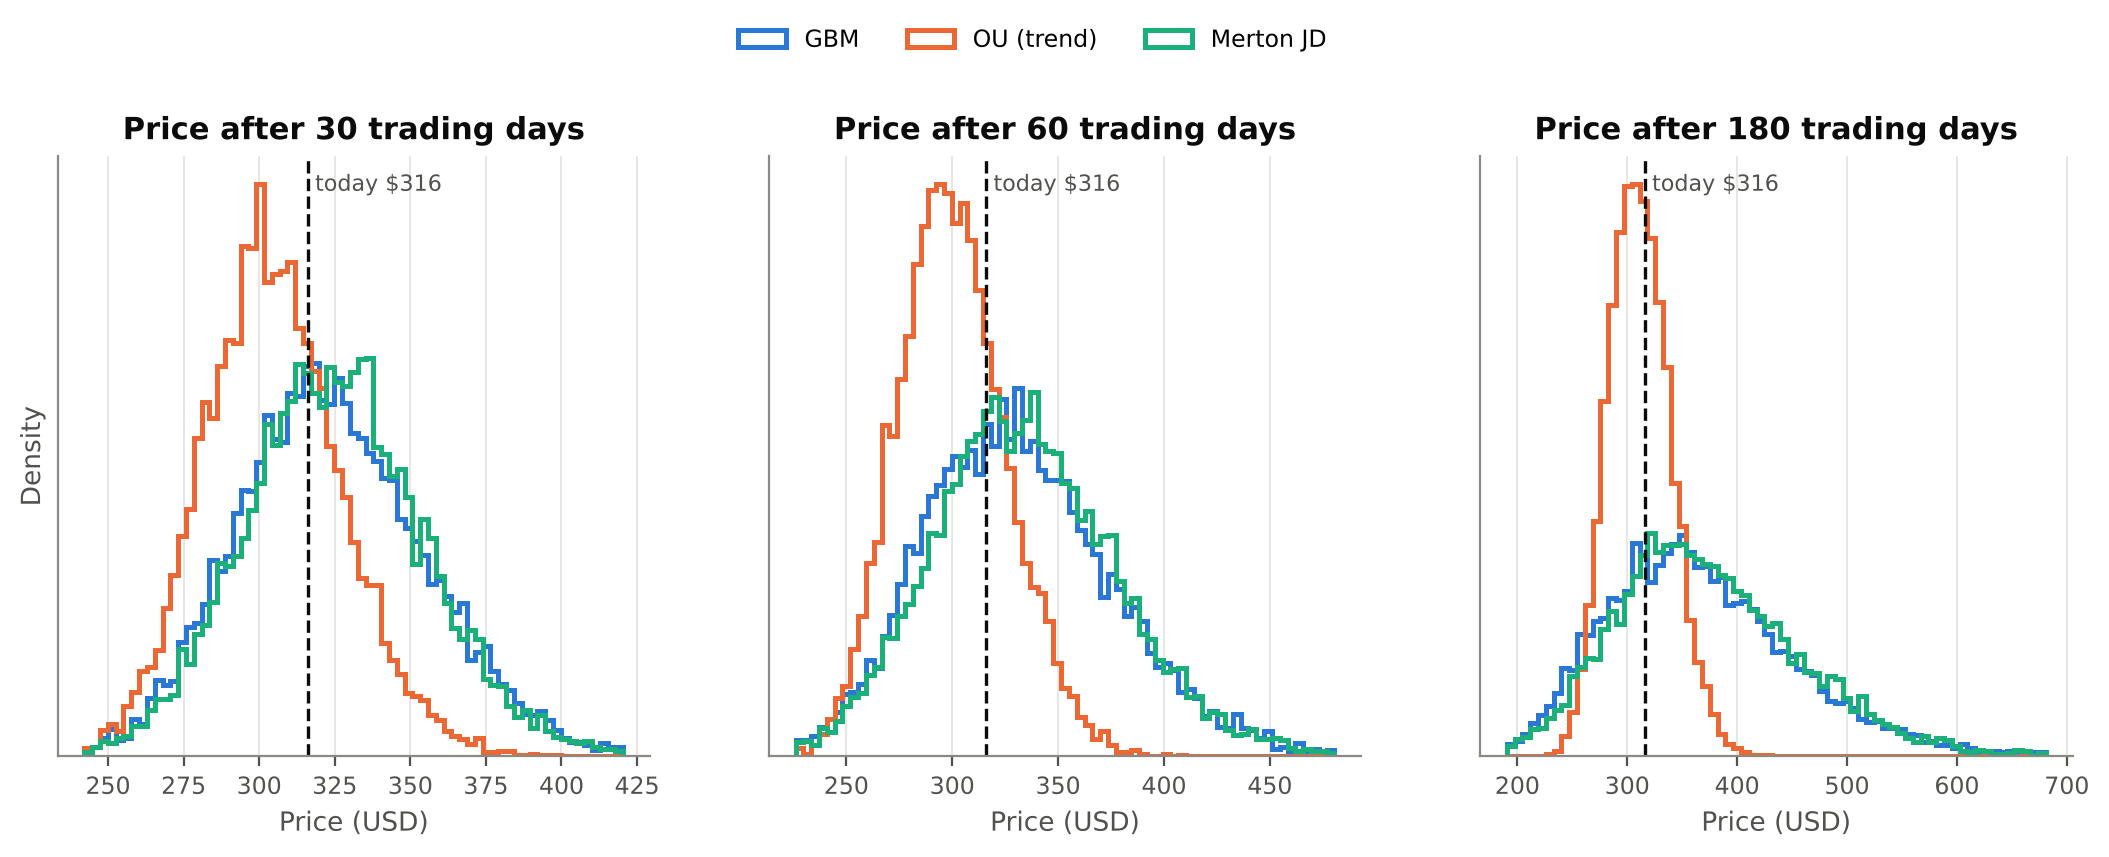

In [14]:
display(Image("figures/fig5_terminal_histograms.png", width=900))

### Probability of loss and 95% VaR by horizon

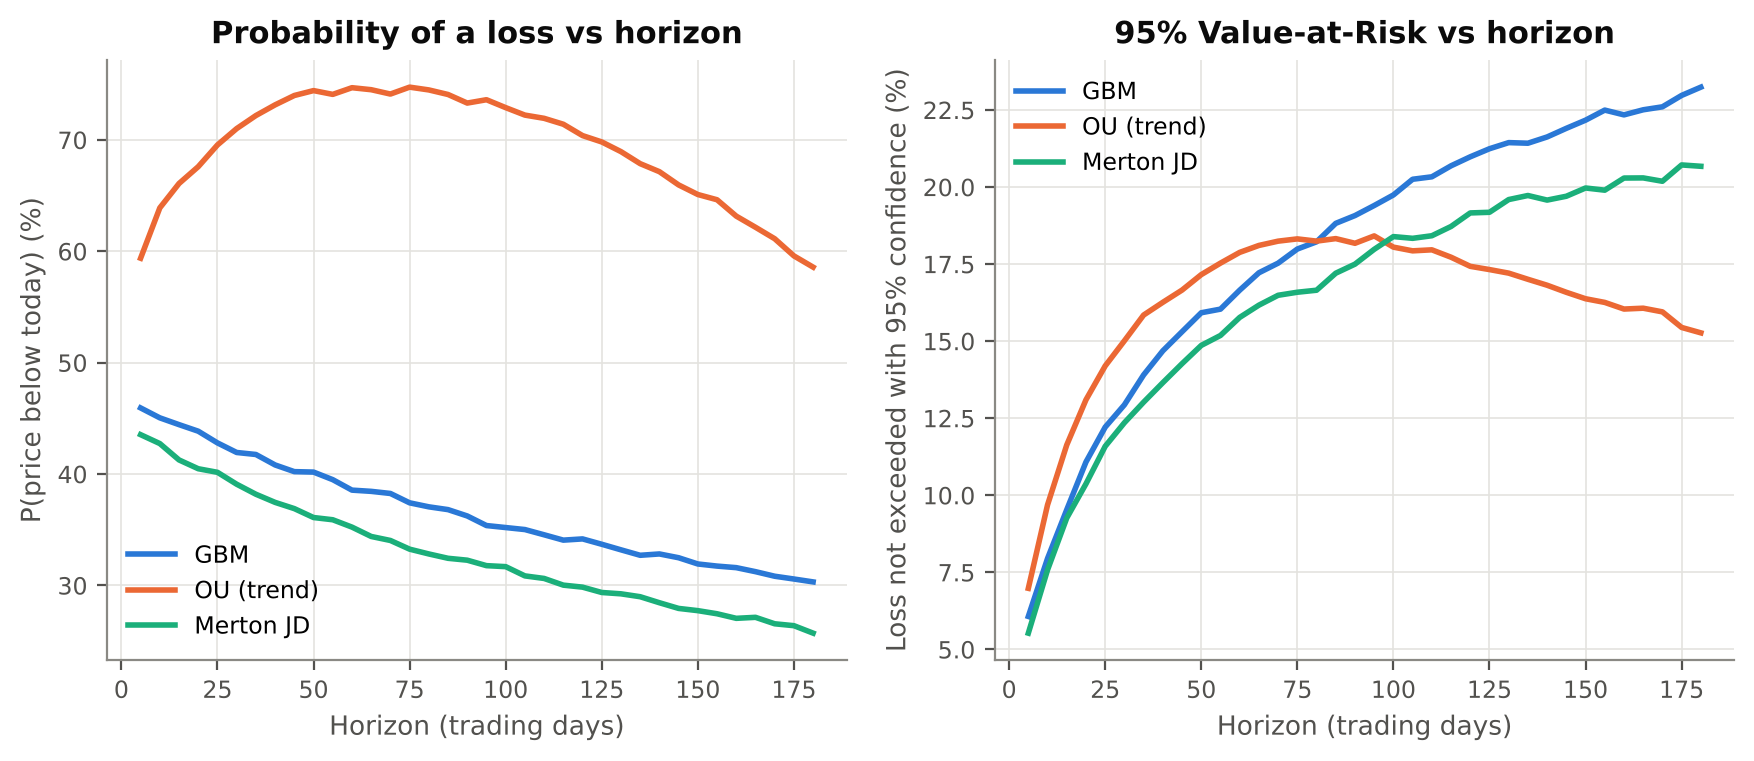

In [15]:
display(Image("figures/fig6_risk_vs_horizon.png", width=900))

### Hold-out test against the realised path

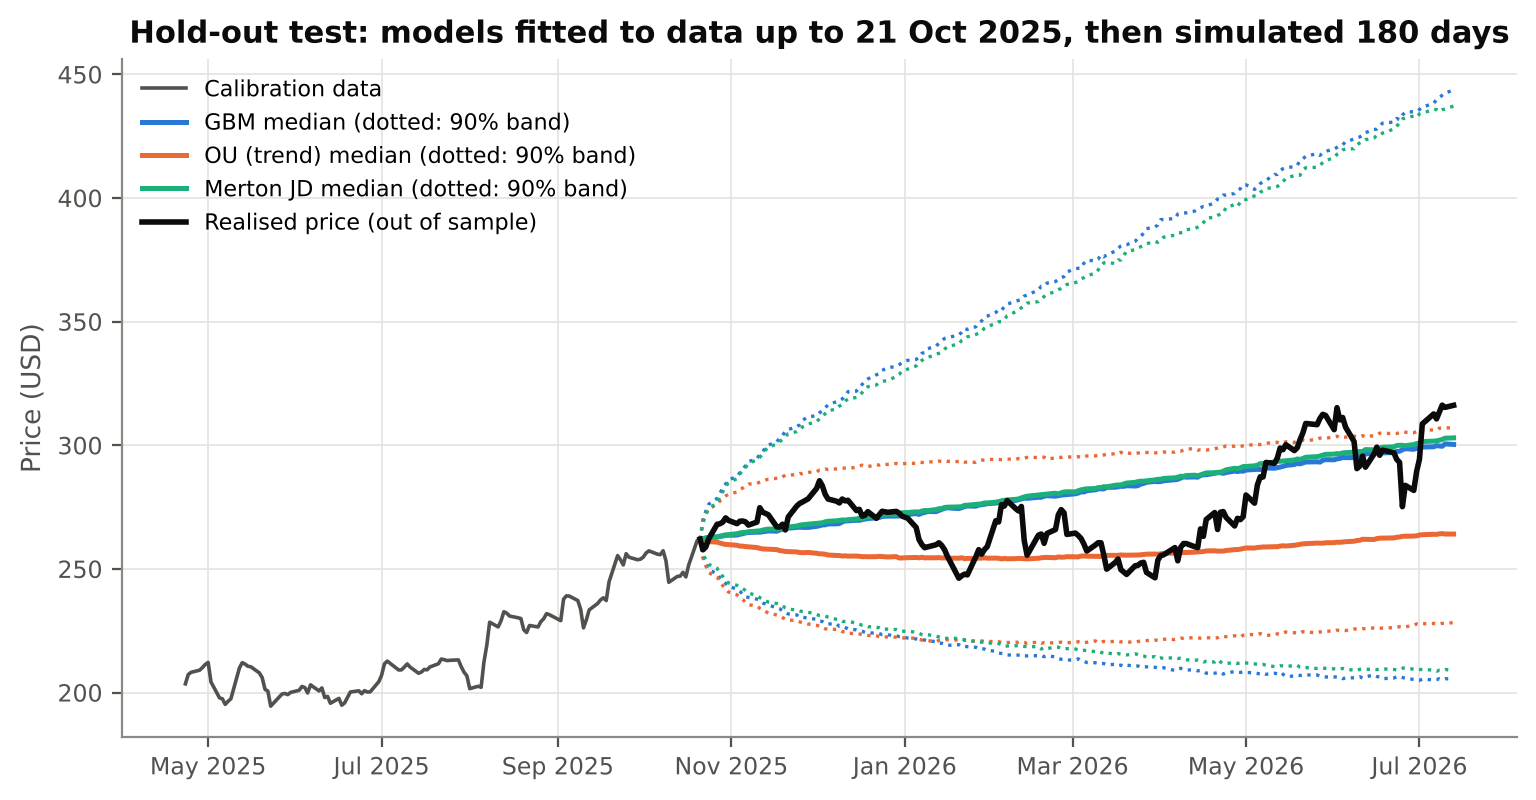

In [16]:
display(Image("figures/fig7_holdout_test.png", width=900))

### Rolling backtest PIT histograms

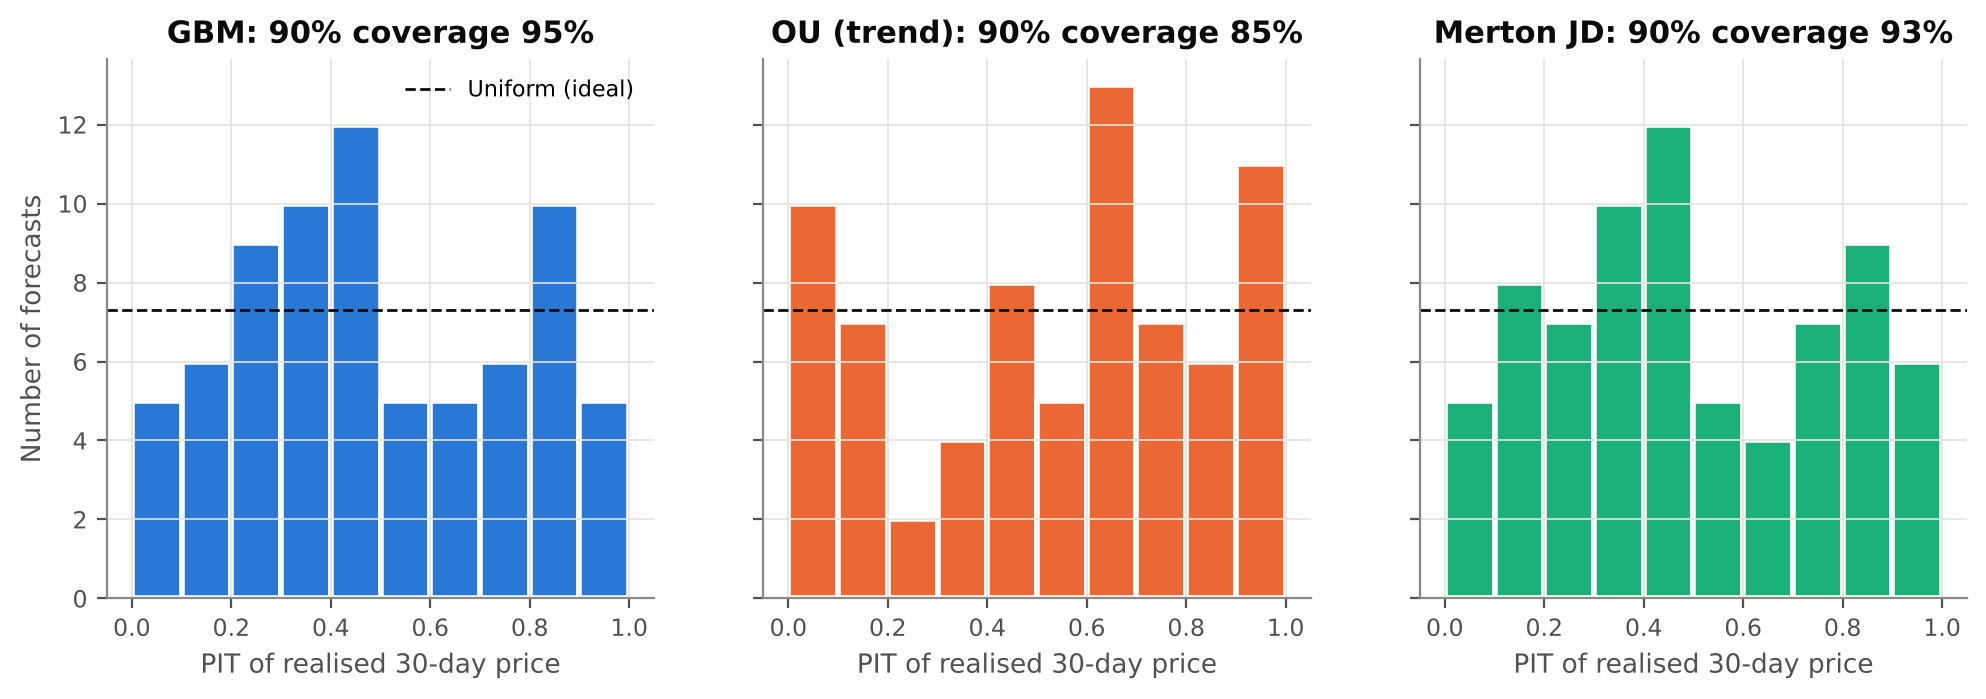

In [17]:
display(Image("figures/fig8_backtest_pit.png", width=900))

## 7. Key takeaways
* GBM and Merton agree on the centre of the distribution: about +16–18% expected over 180 days, from a historical
  drift that is **not** a reliable forecast. Merton has a slightly lower probability of loss but heavier tails.
* The trend-OU model is the only one that leans bearish, because AAPL ended the sample about 14% above its two-year
  log trend. Its intervals are too narrow, though: they covered only 85% of outcomes in the backtest, and the hold-out
  realised price finished above its 95th percentile.
* In the rolling backtest, GBM and Merton intervals are well calibrated (93–95% coverage for a nominal 90%;
  Kupiec p > 0.15). No model shows a reliable directional edge.

See the report for the full interpretation and investor recommendations.